# Integration of Code Quality Features to Estimate LLM Confidence
The datasets: `all_lines_rf_dataset_with_sim` and `all_lines_rf_dataset_no_sim` aims to provide line-related features and to help predict the model confidence. The datasets have the following features (the only difference being the similarity ones between these two): 
<!-- - title -->
- line_row
- any_fix_available
- all_fixes_available
- fix_availability_ratio
- unsafe_fixes
- safe_fixes
- avg_fix_complexity
- max_fix_complexity
- min_fix_complexity
- sum_fix_complexity
- unique_issue_types
- issues_per_line
- A001, ANN001, ANN202, ANN204, ARG001, B007, B905, C901, COM812, D101, D102, D107, E226, E271, E301, E302, E305, E306, E402, E501, E741, F821, F841, I001, N803, N806, PERF401, PLC0415, PLC1901, PLR0913, PLR0914, PLR0917, PLR1730, PLR2004, PLR6104, PLW0603, PLW2901, Q000, RET504, RET505, RET507, RET508, RUF059, SIM110, W291, W292
- class, for, function, if, while
- characters_number
- similarity_2, similarity_3, similarity_4, similarity_5

In [1]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import display
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score, make_scorer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV

## Data Analysis

In [2]:
rf_dataset_sim = pd.read_csv('datasets/all_lines_rf_dataset_with_sim.csv')
rf_dataset_sim['all_fixes_available'] = rf_dataset_sim['all_fixes_available'].map(lambda x: 1 if x else 0)
rf_dataset_sim['any_fix_available'] = rf_dataset_sim['any_fix_available'].map(lambda x: 1 if x else 0)
rf_dataset_sim.head(20)

,title,line_row,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,...,for,function,if,while,characters_number,similarity_2,similarity_3,similarity_4,similarity_5,line_percentage
0,A+BAgain?,1,0,0,0.0,0,0,0.0,0.0,0.0,...,0,0,0,0,14,0.898168,0.849335,0.858385,0.862048,0.142857
1,A+BAgain?,2,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,15,0.769206,0.735990,0.821829,0.860018,0.285714
2,A+BAgain?,3,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,14,0.932981,0.804449,0.845420,0.874074,0.428571
3,A+BAgain?,4,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,16,0.772575,0.777754,0.831880,0.856383,0.571429
4,A+BAgain?,5,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,16,0.817759,0.815602,0.854043,0.862512,0.714286
5,A+BAgain?,6,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,36,0.846163,0.812537,0.853950,0.877656,0.857143
6,A+BAgain?,7,1,1,1.0,0,1,1.0,1.0,1.0,...,1,0,0,0,20,0.711183,0.802041,0.847674,0.867020,1.000000
7,A.WayTooLongWords,1,0,0,0.0,0,0,NaN,NaN,NaN,...,0,1,0,0,20,1.000000,0.916184,0.874611,0.888081,0.047619
8,A.WayTooLongWords,2,0,0,0.0,0,0,NaN,NaN,NaN,...,0,1,1,0,15,1.000000,0.912008,0.893955,0.915207,0.095238
9,A.WayTooLongWords,3,0,0,0.0,0,0,0.0,0.0,0.0,...,0,1,1,0,20,1.000000,0.942011,0.924392,0.939393,0.142857


In [3]:
print(f'There are {rf_dataset_sim.shape[0]} rows and {rf_dataset_sim.shape[1]} columns, excluding the target feature.')

There are 1160 rows and 70 columns, excluding the target feature.


### Missing Data Examination

In [4]:
missing_values = rf_dataset_sim.isnull().sum()
missing_values[missing_values > 0]

avg_fix_complexity     74
max_fix_complexity     74
min_fix_complexity     74
A001                  899
dtype: int64

For these missing values, it is reasonable to replace the NaNs with 0, as a value of 0 appropriately indicates that no fixes or issues were found.

In [5]:
rf_dataset_sim['avg_fix_complexity'] = rf_dataset_sim['avg_fix_complexity'].fillna(0)
rf_dataset_sim['max_fix_complexity'] = rf_dataset_sim['max_fix_complexity'].fillna(0)
rf_dataset_sim['min_fix_complexity'] = rf_dataset_sim['min_fix_complexity'].fillna(0)
rf_dataset_sim['A001'] = rf_dataset_sim['A001'].fillna(0)
rf_dataset_sim.isnull().values.any()

False

In [6]:
rf_dataset_sim.head()

,title,line_row,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,...,for,function,if,while,characters_number,similarity_2,similarity_3,similarity_4,similarity_5,line_percentage
0,A+BAgain?,1,0,0,0.0,0,0,0.0,0.0,0.0,...,0,0,0,0,14,0.898168,0.849335,0.858385,0.862048,0.142857
1,A+BAgain?,2,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,15,0.769206,0.735990,0.821829,0.860018,0.285714
2,A+BAgain?,3,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,14,0.932981,0.804449,0.845420,0.874074,0.428571
3,A+BAgain?,4,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,16,0.772575,0.777754,0.831880,0.856383,0.571429
4,A+BAgain?,5,0,0,0.0,0,0,0.0,0.0,0.0,...,1,0,0,0,16,0.817759,0.815602,0.854043,0.862512,0.714286


### Categorical Features
All categorical features (issues_array, blocks, any_fix_available, all_fixes_available) have already been encoded using binary or one-hot encoding.

In [7]:
rf_dataset_sim['any_fix_available'].value_counts(normalize=True) * 100

any_fix_available
0    83.87931
1    16.12069
Name: proportion, dtype: float64

In [8]:
rf_dataset_sim['all_fixes_available'].value_counts(normalize=True) * 100

all_fixes_available
0    88.017241
1    11.982759
Name: proportion, dtype: float64

For more stats about the categorical features - `stats.ipynb`

### Continous Features

In [9]:
continuous_variables = rf_dataset_sim[['line_row', 'line_percentage', 'unsafe_fixes', 'safe_fixes', 'avg_fix_complexity', 'max_fix_complexity', 'min_fix_complexity', 'sum_fix_complexity', 'unique_issue_types', 'issues_per_line', 'characters_number', 'similarity_2', 'similarity_3', 'similarity_4', 'similarity_5']]
min_continuous_variables = continuous_variables.min(skipna=True)
mean_continuous_variables = continuous_variables.mean(skipna=True)
max_continuous_variables = continuous_variables.max(skipna=True)
std_continuous_variables = continuous_variables.std(skipna=True)
median_continuous_variables = continuous_variables.median(skipna=True)

stats = pd.DataFrame({
    'min': min_continuous_variables,
    'mean': mean_continuous_variables,
    'median': median_continuous_variables,
    'max': max_continuous_variables,
    'std': std_continuous_variables
})

display(stats)

,min,mean,median,max,std
line_row,1.000000,26.996552,21.000000,136.0,24.562786
line_percentage,0.007353,0.512931,0.512854,1.0,0.288782
unsafe_fixes,0.000000,0.024138,0.000000,2.0,0.159064
safe_fixes,0.000000,0.163793,0.000000,9.0,0.554905
avg_fix_complexity,0.000000,0.175000,0.000000,2.0,0.414861
max_fix_complexity,0.000000,0.175000,0.000000,2.0,0.414861
min_fix_complexity,0.000000,0.175000,0.000000,2.0,0.414861
sum_fix_complexity,0.000000,0.201724,0.000000,9.0,0.602552
unique_issue_types,0.000000,0.302586,0.000000,6.0,0.662565
issues_per_line,0.000000,0.402586,0.000000,11.0,1.102586


## Data Visualization
### Categorical Features

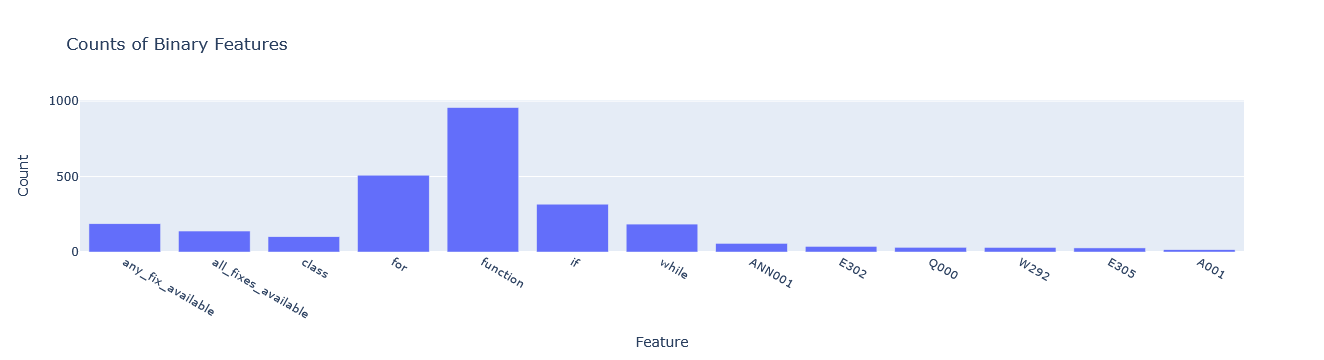

In [10]:
counts = rf_dataset_sim[[
    "any_fix_available",
    "all_fixes_available",
    "class",
    "for",
    "function",
    "if",
    "while",
    "ANN001",
    "E302",
    "Q000",
    "W292",
    "E305",
    "A001",
]].sum()

fig = go.Figure(go.Bar(x=counts.index, y=counts.values))
fig.update_layout(title='Counts of Binary Features', xaxis_title='Feature', yaxis_title='Count')
fig.show()

### Continous Features

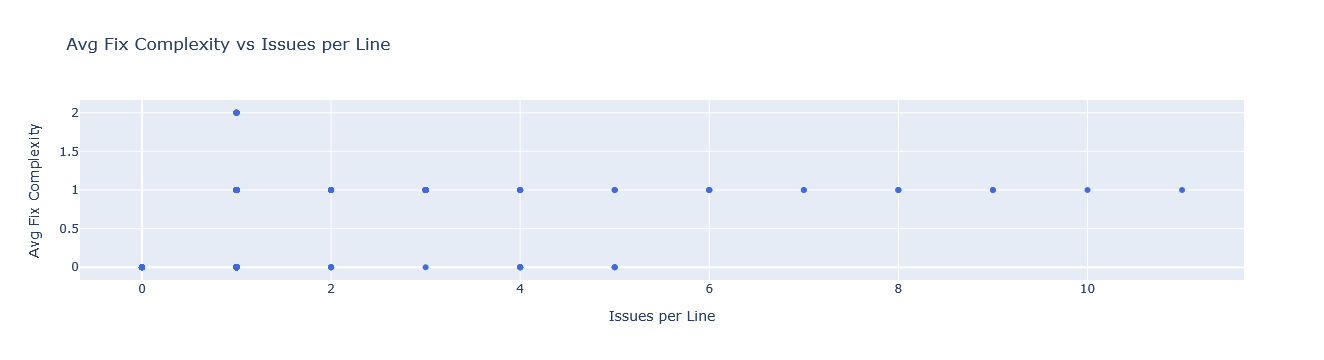

In [11]:
fig = go.Figure(go.Scatter(
    x=rf_dataset_sim['issues_per_line'], y=rf_dataset_sim['avg_fix_complexity'],
    mode='markers',
    marker=dict(color='royalblue'),
    name='Fix Complexity vs Issues/Line'
))
fig.update_layout(title='Avg Fix Complexity vs Issues per Line', xaxis_title='Issues per Line', yaxis_title='Avg Fix Complexity')
fig.show()

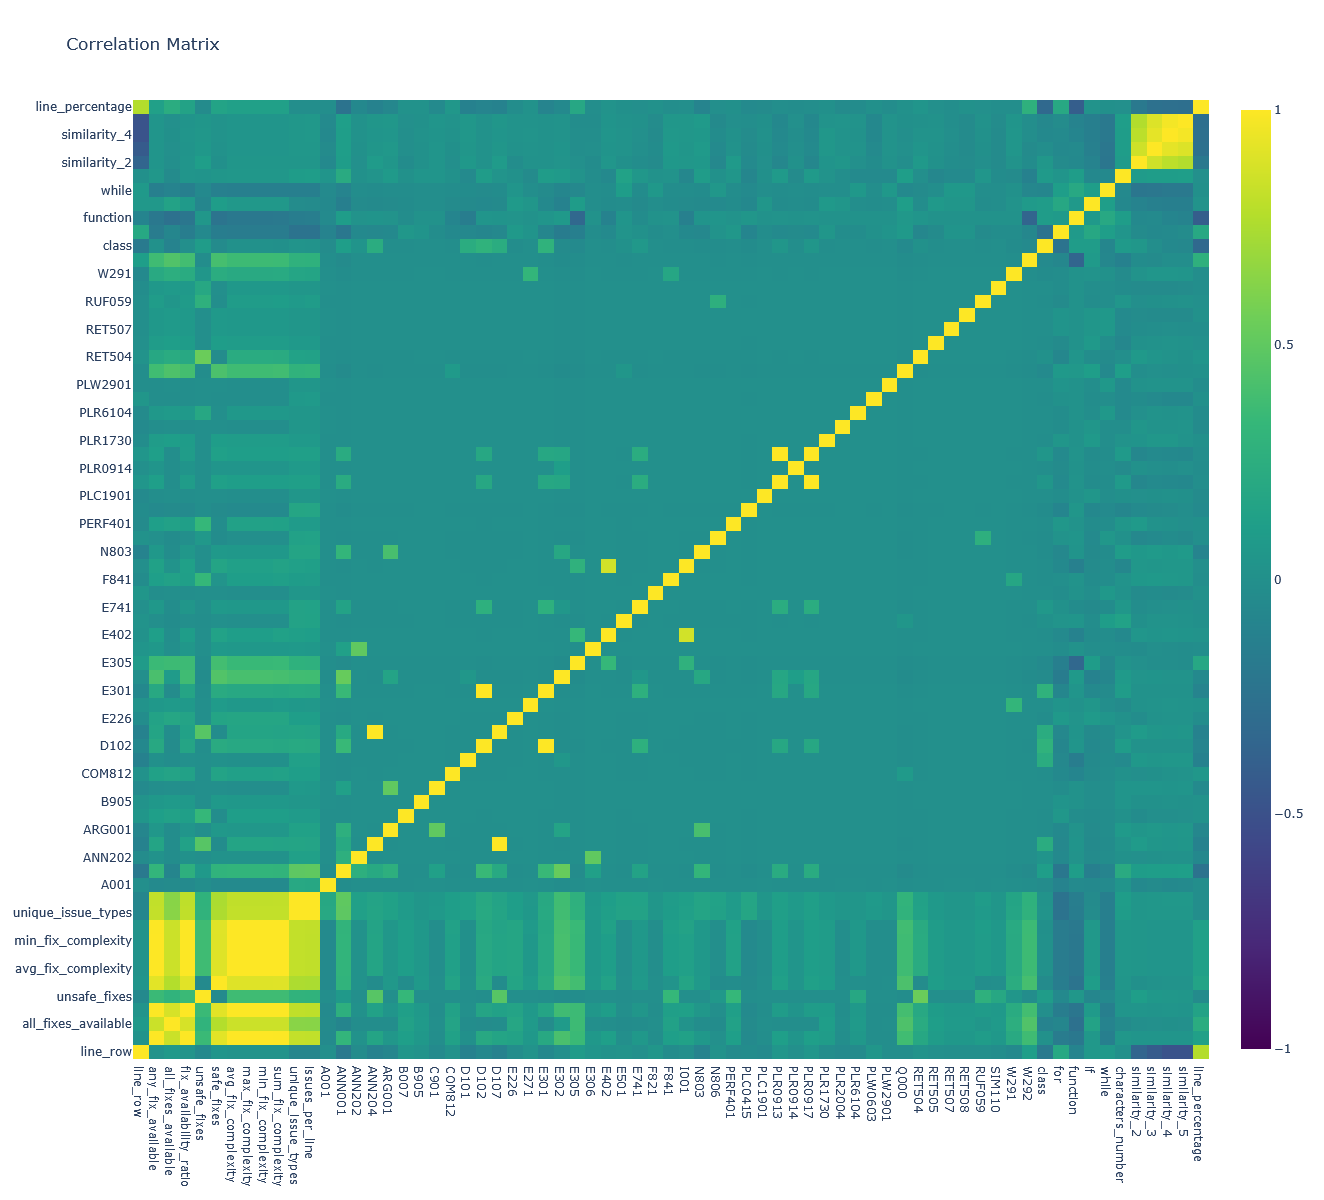

In [12]:
correlation = rf_dataset_sim.corr(method= 'spearman', numeric_only=True)
heatmap = go.Heatmap(
    z=correlation.values,
    x=correlation.columns,
    y=correlation.columns,
    colorscale='Viridis',
    zmin=-1, zmax=1
)
fig = go.Figure(data=heatmap)
fig.update_layout(title='Correlation Matrix', width=1200, height=1200)
fig.show()

In [13]:
correlation

,line_row,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,sum_fix_complexity,...,for,function,if,while,characters_number,similarity_2,similarity_3,similarity_4,similarity_5,line_percentage
line_row,1.000000,0.022575,0.072967,0.030353,-0.056050,0.043441,0.021782,0.021782,0.021782,0.019940,...,0.195629,-0.094544,0.060903,0.074773,0.001277,-0.354344,-0.424990,-0.480373,-0.484834,0.770696
any_fix_available,0.022575,1.000000,0.841647,0.996975,0.352126,0.915130,0.998790,0.998790,0.998790,0.998029,...,-0.165605,-0.199133,0.062588,-0.139737,0.052401,0.041513,0.038124,0.041036,0.036478,0.130348
all_fixes_available,0.072967,0.841647,1.000000,0.880495,0.295248,0.772296,0.845403,0.845403,0.845403,0.844907,...,-0.080196,-0.256215,0.149001,-0.102721,-0.039681,-0.006940,-0.002224,0.002065,-0.003714,0.234422
fix_availability_ratio,0.030353,0.996975,0.880495,1.000000,0.351156,0.912654,0.996446,0.996446,0.996446,0.995824,...,-0.156585,-0.211978,0.076071,-0.137201,0.039051,0.036562,0.033978,0.037273,0.032471,0.148246
unsafe_fixes,-0.056050,0.352126,0.295248,0.351156,1.000000,-0.045561,0.373431,0.373431,0.373431,0.373347,...,-0.055919,0.056063,-0.081844,-0.051640,0.033251,0.107795,0.066279,0.051603,0.047678,-0.042514
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
similarity_2,-0.354344,0.041513,-0.006940,0.036562,0.107795,0.000929,0.044471,0.044471,0.044471,0.045969,...,-0.041027,-0.058270,-0.103435,-0.209678,0.085629,1.000000,0.854891,0.796113,0.767253,-0.188129
similarity_3,-0.424990,0.038124,-0.002224,0.033978,0.066279,0.015866,0.039763,0.039763,0.039763,0.041498,...,-0.055367,-0.048216,-0.126651,-0.202460,0.101005,0.854891,1.000000,0.925052,0.898271,-0.253285
similarity_4,-0.480373,0.041036,0.002065,0.037273,0.051603,0.025094,0.042235,0.042235,0.042235,0.043601,...,-0.046963,-0.090694,-0.134857,-0.187859,0.106193,0.796113,0.925052,1.000000,0.971501,-0.267419
similarity_5,-0.484834,0.036478,-0.003714,0.032471,0.047678,0.020885,0.036968,0.036968,0.036968,0.038346,...,-0.035417,-0.106244,-0.140726,-0.187044,0.113559,0.767253,0.898271,0.971501,1.000000,-0.271085


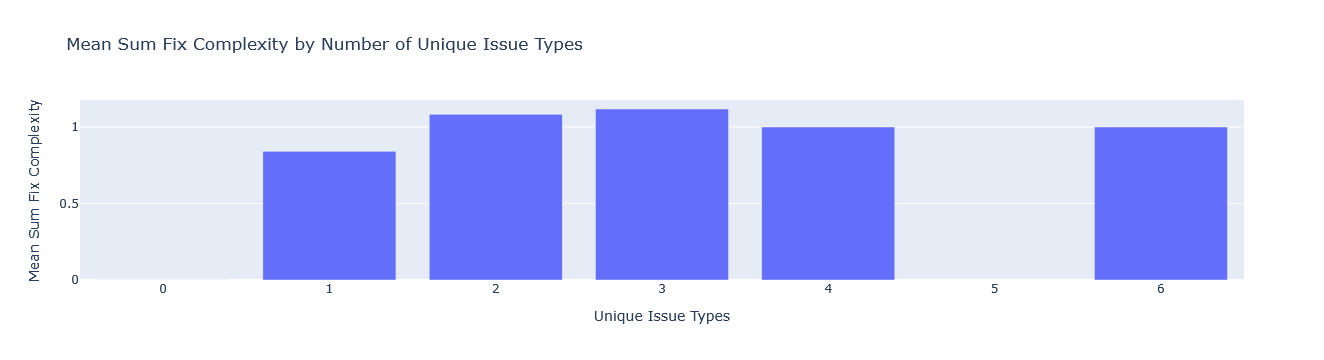

In [14]:
grouped = rf_dataset_sim.groupby('unique_issue_types')['sum_fix_complexity'].mean().reset_index()

fig = go.Figure(go.Bar(
    x=grouped['unique_issue_types'],
    y=grouped['sum_fix_complexity']
))
fig.update_layout(title='Mean Sum Fix Complexity by Number of Unique Issue Types',
                  xaxis_title='Unique Issue Types',
                  yaxis_title='Mean Sum Fix Complexity')
fig.show()

## Modeling - Standard Validation

In [15]:
y = pd.read_csv('datasets/evaluation_python_solutions_1.csv')
y['original_index'] = y.index
y = y.sort_values(by=['problem_title', 'original_index'])['good']
X = rf_dataset_sim.drop(columns=['title', 'similarity_2', 'similarity_3', 'similarity_4', 'line_row'])

In [16]:
param_dist = {
    'n_estimators': list(range(64, 129, 16)), 
    'min_samples_leaf': list(range(1, 21)),    
    'max_features': ['sqrt', 'log2', None]    
}

In [17]:
rf = RandomForestClassifier(random_state=0, class_weight='balanced')
f1 = make_scorer(f1_score, average='binary', pos_label=1)

In [18]:
def search_best_params(X, y):
    search = RandomizedSearchCV(
        rf,
        param_distributions=param_dist,
        n_iter=30,
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=0),
        scoring=f1,
        n_jobs=-1,
        random_state=0
    )
    search = search.fit(X, y)
    f1_test = search.best_score_

    print(f"Best Params: {search.best_params_}")
    print(f"Test F1-score: {f1_test:.4f}")
    return search

print("With Similarity")
search_with_sim = search_best_params(X, y)
print("Without Similarity")
search_without_sim = search_best_params(X.drop(columns=['similarity_5']), y)

With Similarity
Best Params: {'n_estimators': 112, 'min_samples_leaf': 1, 'max_features': 'log2'}
Test F1-score: 0.9261
Without Similarity
Best Params: {'n_estimators': 112, 'min_samples_leaf': 1, 'max_features': 'log2'}
Test F1-score: 0.9270


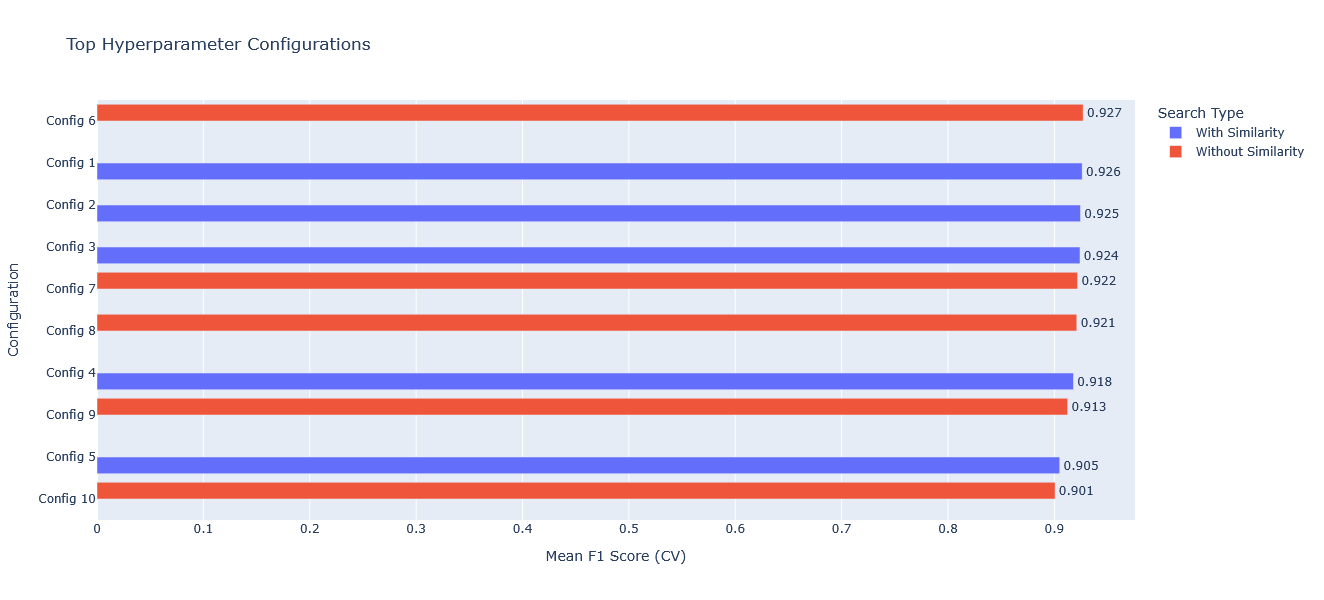

In [19]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

def get_top_n_df(search, label, n=5, offset=0):
    results = pd.DataFrame(search.cv_results_)
    results = results.sort_values(by='mean_test_score', ascending=False).head(n).copy()
    results['Configuration'] = [f"Config {i+1+offset}" for i in range(n)]
    results['Search Type'] = label
    results['Config Details'] = results['params'].apply(
        lambda p: f"n={p['n_estimators']}, leaf={p['min_samples_leaf']}, feat={p['max_features']}"
    )
    return results[['Configuration', 'mean_test_score', 'Search Type', 'Config Details']]

# Prepare combined DataFrame
df_with = get_top_n_df(search_with_sim, "With Similarity", n=5)
df_without = get_top_n_df(search_without_sim, "Without Similarity", n=5, offset=5)
df_combined = pd.concat([df_with, df_without])

# Main plot
fig = px.bar(
    df_combined,
    x='mean_test_score',
    y='Configuration',
    color='Search Type',
    barmode='group',
    orientation='h',
    text='mean_test_score',
    labels={'mean_test_score': 'Mean F1 Score (CV)'},
    title='Top Hyperparameter Configurations'
)

fig.update_traces(texttemplate='%{text:.3f}', textposition='outside')
fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    height=600,
    legend_title_text='Search Type'
)

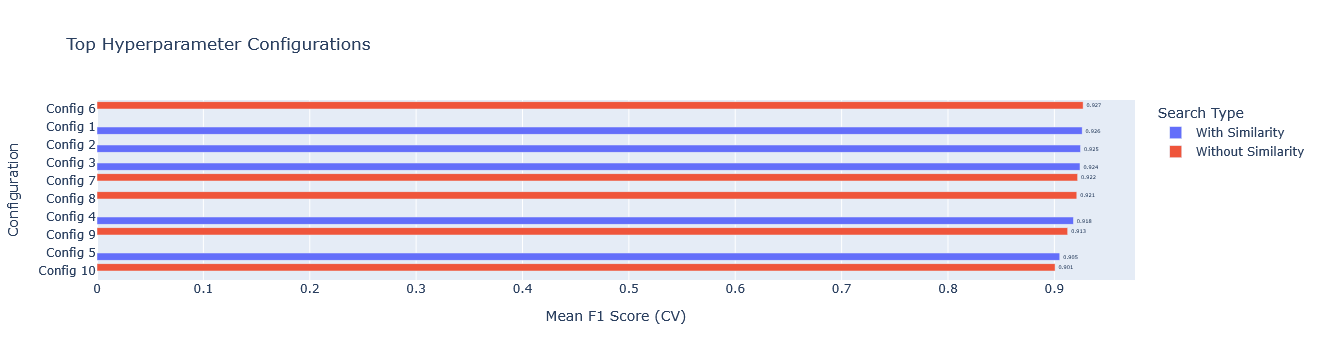

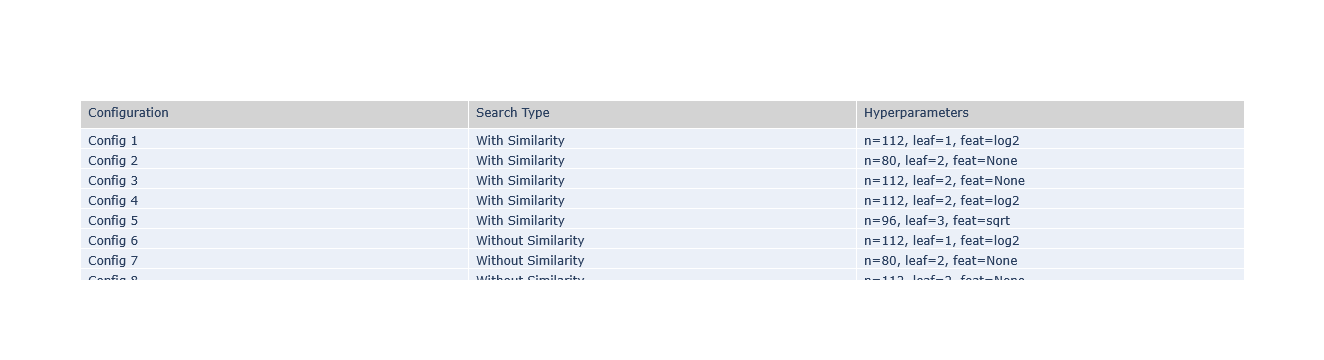

In [20]:
config_table = go.Figure(data=[go.Table(
    header=dict(
        values=["Configuration", "Search Type", "Hyperparameters"],
        fill_color='lightgrey',
        align='left'
    ),
    cells=dict(
        values=[
            df_combined['Configuration'],
            df_combined['Search Type'],
            df_combined['Config Details']
        ],
        align='left'
    )
)])

# Show both plots
fig.show()
config_table.show()

In [ ]:
fig.write_image("top_configs_plot.png")

With Similarity
              feature  importance
62  characters_number    0.306117
64    line_percentage    0.248137
63       similarity_5    0.226995
58                for    0.025267
59           function    0.024945
60                 if    0.024839
61              while    0.018789
10    issues_per_line    0.014863
57              class    0.010530
30               E501    0.009494



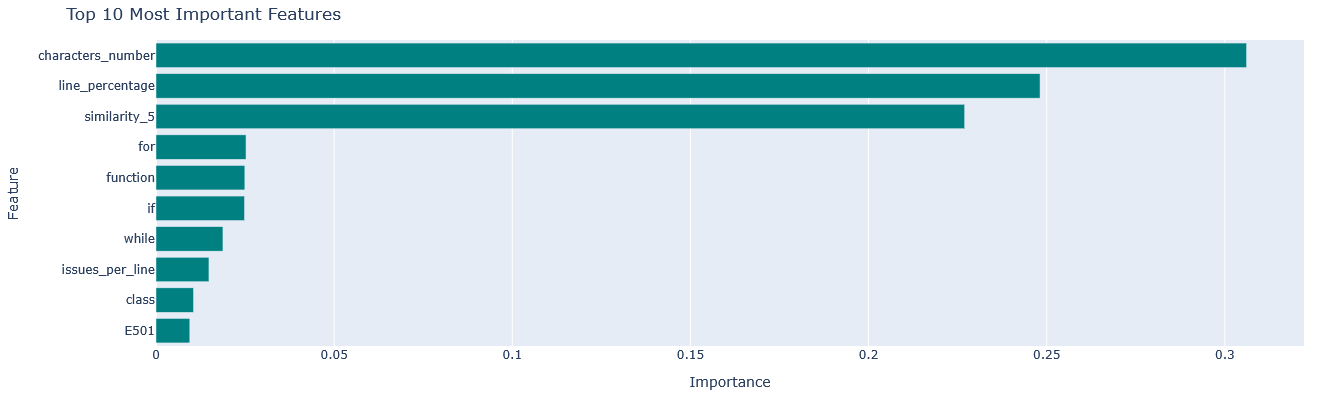

Without Similarity
               feature  importance
62   characters_number    0.401328
63     line_percentage    0.375526
60                  if    0.025529
58                 for    0.022947
59            function    0.022766
61               while    0.018506
10     issues_per_line    0.013838
57               class    0.013329
9   unique_issue_types    0.011400
30                E501    0.010303



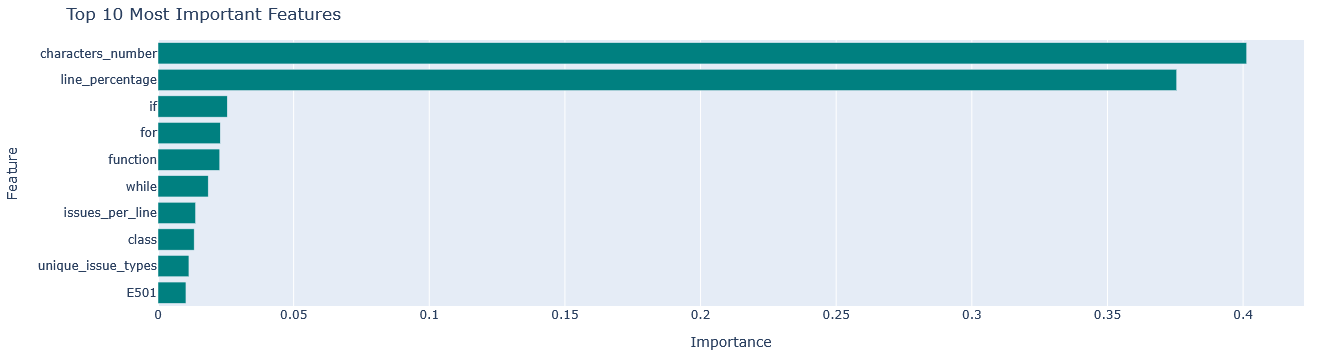

In [22]:
def get_most_important_features(search, X):
    best_rf = search.best_estimator_

    importances = best_rf.feature_importances_
    feature_names = X.columns

    feature_importance_df = pd.DataFrame({
        'feature': feature_names,
        'importance': importances
    }).sort_values(by='importance', ascending=False)

    print(feature_importance_df.head(10))
    print()

    top_n = 10
    top_features = feature_importance_df.head(top_n).sort_values(by='importance')

    fig = go.Figure(go.Bar(
        x=top_features['importance'],
        y=top_features['feature'],
        orientation='h',
        marker=dict(color='teal')
    ))

    fig.update_layout(
        title=f"Top {top_n} Most Important Features",
        xaxis_title="Importance",
        yaxis_title="Feature",
        height=400,
        margin=dict(l=100, r=20, t=40, b=40)
    )

    fig.show()
    return best_rf

print("With Similarity")
best_rf_with_sim = get_most_important_features(search_with_sim, X)

print("Without Similarity")
best_rf_without_sim = get_most_important_features(search_without_sim, X.drop(columns=['similarity_5']))

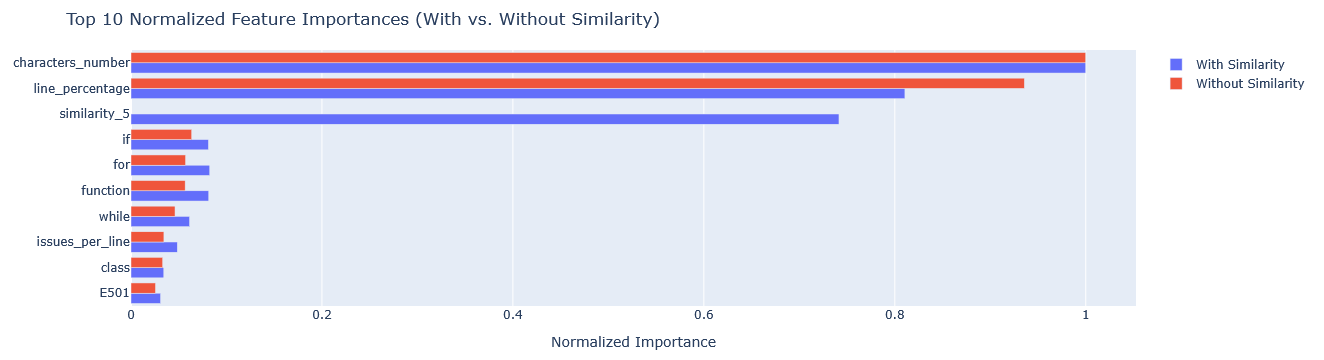

In [23]:
import pandas as pd
import plotly.graph_objects as go
from sklearn.preprocessing import MinMaxScaler

def get_normalized_feature_importances(search, X, label):
    best_rf = search.best_estimator_
    importances = best_rf.feature_importances_
    feature_names = X.columns

    df = pd.DataFrame({
        'feature': feature_names,
        'importance': importances
    })

    # Normalize importance values to [0, 1] for fair comparison
    df['importance'] = MinMaxScaler().fit_transform(df[['importance']])
    df['model'] = label
    return df

# Get normalized importances
df_with_sim = get_normalized_feature_importances(search_with_sim, X, 'With Similarity')
df_without_sim = get_normalized_feature_importances(search_without_sim, X.drop(columns=['similarity_5']), 'Without Similarity')

# Combine and filter top N features overall
combined_df = pd.concat([df_with_sim, df_without_sim])
top_features = combined_df.groupby('feature')['importance'].max().nlargest(10).index.tolist()
plot_df = combined_df[combined_df['feature'].isin(top_features)]

# Sort y-axis labels by mean importance
y_order = plot_df.groupby('feature')['importance'].mean().sort_values().index

# Create grouped bar chart
fig = go.Figure()

for model in plot_df['model'].unique():
    model_data = plot_df[plot_df['model'] == model]
    fig.add_trace(go.Bar(
        x=model_data['importance'],
        y=model_data['feature'],
        name=model,
        orientation='h'
    ))

fig.update_layout(
    title="Top 10 Normalized Feature Importances (With vs. Without Similarity)",
    xaxis_title="Normalized Importance",
    yaxis=dict(categoryorder='array', categoryarray=y_order),
    barmode='group',
    height=500,
    margin=dict(l=120, r=20, t=50, b=40)
)

fig.show()

Use the Model for Estimating the Confidence

In [24]:
def get_folds(X, y, k=5):
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=0)
    split_index = []
    for i, (train_index, test_index) in enumerate(skf.split(X, y)):
        split_index.append([train_index, test_index])
    return split_index

split_index = get_folds(X, y)

In [25]:
X_with_predictions = X.copy()
X_with_predictions['prob_class_1_with_sim'] = np.nan
X_with_predictions['prob_class_1_without_sim'] = np.nan

split_index_with_sim = get_folds(X, y)
split_index_without_sim = get_folds(X.drop(columns=['similarity_5']), y)

def set_predictions(X, params, split_index, mode=0, store=1):
    f1_scores = []
    for split in split_index:
        X_train_split = pd.DataFrame()
        y_train_split = pd.DataFrame()
        
        X_split_train_dataset = X.iloc[split[0]]
        y_split_train_dataset = y.iloc[split[0]]

        X_train_split = pd.concat([X_train_split, X_split_train_dataset], ignore_index=False)
        y_train_split = pd.concat([y_train_split, y_split_train_dataset], ignore_index=False)

        split_rf = RandomForestClassifier(**params, class_weight='balanced', random_state=0)
        split_rf.fit(X_train_split, y_train_split.values.ravel())

        X_test_split = X.iloc[split[1]]
        proba = split_rf.predict_proba(X_test_split)
        y_pred = split_rf.predict(X_test_split)
        y_test_split = y.iloc[split[1]]
        f1_test = f1_score(y_test_split, y_pred, pos_label=1)
        f1_scores.append(f1_test)
        
        train_indices = X_train_split.index
        test_indices = X_test_split.index
        # print("Train/Test overlap:", len(set(train_indices) & set(test_indices)))

        proba_class_1 = proba[:, 1]
        results_df = X_test_split.copy()
        results_df['prob_class_1'] = proba_class_1
        label = 'prob_class_1_with_sim' if mode == 0 else 'prob_class_1_without_sim'
        if store:
            X_with_predictions.loc[X_test_split.index, label] = results_df['prob_class_1']
    
    if not store:
        return f1_scores

set_predictions(X, search_with_sim.best_params_, split_index_with_sim)
set_predictions(X.drop(columns=['similarity_5']), search_without_sim.best_params_, split_index_without_sim, 1)

In [26]:
X_with_predictions.head()

,any_fix_available,all_fixes_available,fix_availability_ratio,unsafe_fixes,safe_fixes,avg_fix_complexity,max_fix_complexity,min_fix_complexity,sum_fix_complexity,unique_issue_types,...,class,for,function,if,while,characters_number,similarity_5,line_percentage,prob_class_1_with_sim,prob_class_1_without_sim
0,0,0,0.0,0,0,0.0,0.0,0.0,0.0,0,...,0,0,0,0,0,14,0.862048,0.142857,0.508929,0.375000
1,0,0,0.0,0,0,0.0,0.0,0.0,0.0,0,...,0,1,0,0,0,15,0.860018,0.285714,0.752382,0.875000
2,0,0,0.0,0,0,0.0,0.0,0.0,0.0,0,...,0,1,0,0,0,14,0.874074,0.428571,0.678571,0.678571
3,0,0,0.0,0,0,0.0,0.0,0.0,0.0,0,...,0,1,0,0,0,16,0.856383,0.571429,0.848214,0.928571
4,0,0,0.0,0,0,0.0,0.0,0.0,0.0,0,...,0,1,0,0,0,16,0.862512,0.714286,0.830357,0.946429


In [27]:
split_index_with_sim = get_folds(X, y, 30)
split_index_without_sim = get_folds(X.drop(columns=['similarity_5']), y, 30)
f1_score_sim = set_predictions(X, search_with_sim.best_params_, split_index_with_sim, 0, 0)
f1_score_no_sim = set_predictions(X.drop(columns=['similarity_5']), search_without_sim.best_params_, split_index_without_sim, 1, 0)

In [28]:
from scipy.stats import wilcoxon

stat, p = wilcoxon(f1_score_sim, f1_score_no_sim)
print(f"Wilcoxon test statistic = {stat}, p-value = {p}")
if p < 0.05:
    print("The difference in F1 scores is statistically significant.")
else:
    print("No statistically significant difference.")

Wilcoxon test statistic = 121.5, p-value = 0.10484522524442566
No statistically significant difference.


In [30]:
import numpy as np
from scipy.stats import rankdata

# Your paired scores
diff = np.array(f1_score_sim) - np.array(f1_score_no_sim)
non_zero_diff = diff[diff != 0]
abs_diff = np.abs(non_zero_diff)
ranks = rankdata(abs_diff)

# Compute W+ and W-
W_plus = np.sum(ranks[non_zero_diff > 0])
W_minus = np.sum(ranks[non_zero_diff < 0])

# Rank-biserial correlation
r_rb = (W_plus - W_minus) / (len(non_zero_diff) * (len(non_zero_diff) + 1) / 2)

print(f"Rank-biserial correlation = {r_rb:.4f}")

Rank-biserial correlation = 0.3571


In [29]:
from scipy.stats import ttest_rel

stat, p = ttest_rel(f1_score_sim, f1_score_no_sim)
print(f"Paired t-test statistic = {stat}, p-value = {p}")

Paired t-test statistic = 1.444282691714815, p-value = 0.15937766107864393


## Add Probabilities

In [27]:
all_probabilities = pd.read_csv('datasets/all_probabilities.csv')
all_probabilities = all_probabilities.sort_values(by=['title', 'line_number'])
all_probabilities.head()

,title,line_number,line_text,token_prob,similarity_2,similarity_3,similarity_4,similarity_5,rf_with_sim,rf_without_sim
0,A+B Again?,1,t = int(input())\n\n,0.935992,0.898168,0.849335,0.858385,0.862048,0.508929,0.375000
1,A+B Again?,2,for _ in range(t):\n,0.993529,0.769206,0.735990,0.821829,0.860018,0.752382,0.875000
2,A+B Again?,3,n = int(input())\n,0.999838,0.932981,0.804449,0.845420,0.874074,0.678571,0.678571
3,A+B Again?,4,tens_digit = n // 10\n \n,0.998948,0.772575,0.777754,0.831880,0.856383,0.848214,0.928571
4,A+B Again?,5,units_digit = n % 10\n \n,0.999998,0.817759,0.815602,0.854043,0.862512,0.830357,0.946429


In [28]:
all_probabilities['rf_with_sim'] = X_with_predictions['prob_class_1_with_sim']
all_probabilities['rf_without_sim'] = X_with_predictions['prob_class_1_without_sim']
all_probabilities.head()

,title,line_number,line_text,token_prob,similarity_2,similarity_3,similarity_4,similarity_5,rf_with_sim,rf_without_sim
0,A+B Again?,1,t = int(input())\n\n,0.935992,0.898168,0.849335,0.858385,0.862048,0.508929,0.375000
1,A+B Again?,2,for _ in range(t):\n,0.993529,0.769206,0.735990,0.821829,0.860018,0.752382,0.875000
2,A+B Again?,3,n = int(input())\n,0.999838,0.932981,0.804449,0.845420,0.874074,0.678571,0.678571
3,A+B Again?,4,tens_digit = n // 10\n \n,0.998948,0.772575,0.777754,0.831880,0.856383,0.848214,0.928571
4,A+B Again?,5,units_digit = n % 10\n \n,0.999998,0.817759,0.815602,0.854043,0.862512,0.830357,0.946429


In [29]:
all_probabilities.to_csv('datasets/all_probabilities.csv', index=False)